In [1]:
import math
import pickle
import itertools
from pathlib import Path
from collections import defaultdict, Counter
from itertools import combinations

import numpy as np
import polars as pl
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.linestyle': '--',
    'grid.alpha': 0.4,
})

np.random.seed(420)

## 1. Data Loading

In [2]:
class CloudscapeDataset:
    def __init__(self, df_architectures, df_nodes, df_edges, graphs):
        self.architectures = df_architectures
        self.nodes = df_nodes
        self.edges = df_edges
        self.graphs = graphs


BASE_DIR = Path(".")
DATA_DIR = BASE_DIR / "data"
SERVICES_CSV = DATA_DIR / "services.csv"
BUNDLE_PATH = BASE_DIR / "output_analytics" / "cloudscape_pipeline_bundle.pkl"

if not BUNDLE_PATH.exists():
    raise FileNotFoundError(f"Bundle not found at {BUNDLE_PATH}")

with open(BUNDLE_PATH, "rb") as f:
    bundle = pickle.load(f)

df_services_master: pl.DataFrame = bundle["df_services_master"]
df_cooccurrences: pl.DataFrame = bundle["df_cooccurrences"]
df_transitions = bundle.get("df_transitions")
G_cooc_master: nx.Graph = bundle["G_cooc_master"]

print(f"Services in graph: {G_cooc_master.number_of_nodes()}")
print(f"Edges: {G_cooc_master.number_of_edges()}")
print(f"Services in catalog: {df_services_master.height}")

Services in graph: 78
Edges: 491
Services in catalog: 160


## 2. Common Utilities

In [3]:
df_services_cat = pl.read_csv(SERVICES_CSV).select(['name', 'aws_product_categories'])
cat_map_raw = {}
for row in df_services_cat.iter_rows(named=True):
    cats = [c.strip() for c in row['aws_product_categories'].split(',')] if row['aws_product_categories'] else []
    cat_map_raw[row['name']] = cats

GROUP_MAPPING = {
    'Compute': ['Compute'],
    'Storage': ['Storage'],
    'Networking': ['Networking and Content Delivery'],
    'Integration': ['Application Integration'],
    'Analytics': ['Analytics'],
    'Security': ['Security Identity and Compliance'],
    'Management': ['Management and Governance'],
    'IoT': ['IoT'],
    'Media': ['Media Services'],
    'Developer': ['Developer Tools'],
    'Database': ['Database'],
    'ML': ['ML'],
    'Other': [],
}


def get_service_category(service: str) -> str:
    cats = cat_map_raw.get(service, [])
    for group, keywords in GROUP_MAPPING.items():
        for kw in keywords:
            if any(kw in c for c in cats):
                return group
    cap_rows = df_services_master.filter(pl.col('service') == service)['capability']
    cap = cap_rows.first() if len(cap_rows) > 0 else None
    return {
        'compute': 'Compute', 'storage': 'Storage',
        'networking': 'Networking', 'integration': 'Integration',
    }.get(cap, 'Other')


POPULARITY = {
    row['service']: row['num_architectures']
    for row in df_services_master.iter_rows(named=True)
}
BASE_WEIGHT = {
    row['service']: row['base_prob_weight']
    for row in df_services_master.iter_rows(named=True)
}


def popularity(service: str) -> int:
    return POPULARITY.get(service, 0)


def base_weight(service: str) -> float:
    return BASE_WEIGHT.get(service, 0.0)


def are_incompatible(s1: str, s2: str, G: nx.Graph = None) -> bool:
    if G is None:
        G = G_cooc_master
    if s1 == s2:
        return False
    if not G.has_node(s1) or not G.has_node(s2):
        return True
    return not G.has_edge(s1, s2)


def has_internal_conflict(service: str, members: list, G: nx.Graph = None):
    if G is None:
        G = G_cooc_master
    for m in members:
        if are_incompatible(service, m, G):
            return m
    return None


def has_conflict_with_other_dice(service: str, dice: dict, exclude=None, G: nx.Graph = None):
    if G is None:
        G = G_cooc_master
    for die_id, members in dice.items():
        if die_id == exclude:
            continue
        conflict = has_internal_conflict(service, members, G)
        if conflict:
            return (die_id, conflict)
    return None


def incompatibility_rate(service: str, group: list, G: nx.Graph = None) -> float:
    if G is None:
        G = G_cooc_master
    if not group:
        return 0.0
    clashes = sum(1 for o in group if are_incompatible(service, o, G))
    return clashes / len(group)


def find_global_conflicts(dice: dict, G: nx.Graph = None):
    if G is None:
        G = G_cooc_master
    conflicts = []
    ids = list(dice.keys())
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            for s1 in dice[ids[i]]:
                for s2 in dice[ids[j]]:
                    if are_incompatible(s1, s2, G):
                        conflicts.append((ids[i], s1, ids[j], s2))
    return conflicts


CENTRALITY_WEIGHTS = {
    'pagerank': 0.30,
    'degree_centrality': 0.25,
    'betweenness': 0.20,
    'eigenvector': 0.15,
    'closeness': 0.10,
}
assert abs(sum(CENTRALITY_WEIGHTS.values()) - 1.0) < 1e-9, "Weights must sum to 1.0"

## 3. Centrality

In [4]:
def compute_centrality(G: nx.Graph = None) -> pl.DataFrame:
    if G is None:
        G = G_cooc_master
    pagerank = nx.pagerank(G, weight='weight')
    degree_centrality = nx.degree_centrality(G)
    betweenness = nx.betweenness_centrality(G, weight='weight')
    closeness = nx.closeness_centrality(G, distance='weight')
    try:
        eigenvector = nx.eigenvector_centrality(G, weight='weight', max_iter=1000)
    except nx.PowerIterationFailedConvergence:
        eigenvector = nx.eigenvector_centrality_numpy(G, weight='weight')

    rows = []
    for s in G.nodes():
        rows.append({
            'service': s,
            'num_architectures': popularity(s),
            'degree': G.degree(s),
            'pagerank': pagerank.get(s, 0),
            'degree_centrality': degree_centrality.get(s, 0),
            'betweenness': betweenness.get(s, 0),
            'closeness': closeness.get(s, 0),
            'eigenvector': eigenvector.get(s, 0),
        })
    df = pl.DataFrame(rows)
    for col in ['pagerank', 'degree_centrality', 'betweenness', 'closeness', 'eigenvector']:
        max_val = df[col].max()
        if max_val and max_val > 0:
            df = df.with_columns((pl.col(col) / max_val).alias(col))

    df = df.with_columns(
        sum(w * pl.col(col) for col, w in CENTRALITY_WEIGHTS.items()).round(10).alias('centrality_score')
    )
    df = df.with_columns(
        pl.when(pl.col('centrality_score') > 0.5).then(pl.lit('Fundamental'))
        .when(pl.col('centrality_score') > 0.3).then(pl.lit('Integrator'))
        .otherwise(pl.lit('Specialized')).alias('level')
    )
    return df.sort(['centrality_score', 'service'], descending=[True, False])


df_centrality = compute_centrality(G_cooc_master)

CENTRALITY = {
    row['service']: row['centrality_score']
    for row in df_centrality.iter_rows(named=True)
}


def centrality(service: str) -> float:
    return CENTRALITY.get(service, 0.0)


print(df_centrality.select(['service', 'centrality_score', 'level']).head(15))

shape: (15, 3)
┌────────────┬──────────────────┬─────────────┐
│ service    ┆ centrality_score ┆ level       │
│ ---        ┆ ---              ┆ ---         │
│ str        ┆ f64              ┆ str         │
╞════════════╪══════════════════╪═════════════╡
│ S3         ┆ 1.0              ┆ Fundamental │
│ Lambda     ┆ 0.837481         ┆ Fundamental │
│ EC2        ┆ 0.597545         ┆ Fundamental │
│ DynamoDB   ┆ 0.584912         ┆ Fundamental │
│ ApiGateway ┆ 0.479511         ┆ Integrator  │
│ …          ┆ …                ┆ …           │
│ SageMaker  ┆ 0.294461         ┆ Specialized │
│ Athena     ┆ 0.282564         ┆ Specialized │
│ SNS        ┆ 0.264696         ┆ Specialized │
│ Aurora     ┆ 0.26             ┆ Specialized │
│ CloudFront ┆ 0.259672         ┆ Specialized │
└────────────┴──────────────────┴─────────────┘


## 4. Dice Construction Method

### 4.1 Detection of Toxic-Central Services

In [5]:
def identify_toxic_central(df_centrality: pl.DataFrame, pool_total: list,
                                  G: nx.Graph = None,
                                  centrality_threshold: float = 0.3,
                                  toxicity_threshold: float = 0.5,
                                  verbose: bool = True) -> list:
    if G is None:
        G = G_cooc_master

    candidates = df_centrality.filter(
        (pl.col('service').is_in(pool_total)) &
        (pl.col('centrality_score') >= centrality_threshold)
    )

    toxic = []
    for row in candidates.iter_rows(named=True):
        s = row['service']
        rest = [o for o in pool_total if o != s]
        rate = incompatibility_rate(s, rest, G)
        if rate >= toxicity_threshold:
            toxic.append((s, row['centrality_score'], rate))

    toxic.sort(key=lambda t: (-t[1], -t[2]))

    if verbose:
        print(f"Toxic-central services detected: {len(toxic)}")
        for s, cent, rate in toxic:
            print(f"  {s}: centrality={cent:.3f}  toxicity={rate:.2f}")

    return [s for s, _, _ in toxic]

### 4.2 Core by Category, Ranked by Centrality

In [6]:
def _filter_toxic(candidates: list, reference_groups: list, thresholds: list, G: nx.Graph = None):
    if G is None:
        G = G_cooc_master
    sociable, toxic = [], []
    for c in candidates:
        rates = [incompatibility_rate(c, group, G) for group in reference_groups]
        if all(t <= u for t, u in zip(rates, thresholds)):
            sociable.append(c)
        else:
            toxic.append(c)
    return sociable, toxic


def _rank_by_centrality(candidates: list, external_group: list, G: nx.Graph = None) -> list:
    if G is None:
        G = G_cooc_master
    ranking = []
    for c in candidates:
        ext_incompat = sum(1 for o in external_group if are_incompatible(c, o, G))
        ranking.append((ext_incompat, -centrality(c), c))
    ranking.sort()
    return [c for _, _, c in ranking]


def _build_category_core(category_name: str, category_candidates: list,
                                   external_groups: list, toxicity_thresholds: list,
                                   created_dice: dict, n_dice: int, target_faces: int,
                                   G: nx.Graph = None, verbose: bool = True):
    if G is None:
        G = G_cooc_master
    total_external_group = [s for g in external_groups for s in g]
    sociable, toxic = _filter_toxic(category_candidates, external_groups, toxicity_thresholds, G)
    pool = sociable if sociable else category_candidates
    ranked = _rank_by_centrality(pool, total_external_group, G)

    n_dice = max(1, n_dice)
    faces_per_die = max(1, target_faces)
    total_selected = ranked[: n_dice * faces_per_die]
    leftovers = ranked[n_dice * faces_per_die:] + toxic

    groups = [[] for _ in range(n_dice)]
    for idx, s in enumerate(total_selected):
        groups[idx % n_dice].append(s)

    for i, members in enumerate(groups):
        if not members:
            continue
        die_id = f"Die_{category_name}" if n_dice == 1 else f"Die_{category_name}_{i + 1}"
        created_dice[die_id] = members
        if verbose:
            print(f"{die_id}: {members}")

    returned, discarded = [], []
    for s in leftovers:
        conflict = has_conflict_with_other_dice(s, created_dice, exclude=None, G=G)
        if conflict:
            discarded.append(s)
            if verbose:
                print(f"Discarded {s}: incompatible with {conflict[1]}")
        else:
            returned.append(s)
    return returned, discarded


def build_core(
        df_services_master: pl.DataFrame,
        G: nx.Graph = None,
        min_archs_threshold: int = 20,
        max_incompat_compute_storage: float = 0.40,
        max_incompat_compute_rest: float = 0.30,
        max_incompat_storage_rest: float = 0.50,
        target_faces_per_die: int = 4,
        min_faces_per_die: int = 3,
        max_faces_per_die: int = 6,
        exclude: list = None,
        verbose: bool = True,
):
    if G is None:
        G = G_cooc_master
    exclude = set(exclude or [])

    df_aws = df_services_master.filter(
        (pl.col('is_aws') == True) & (pl.col('num_architectures') >= min_archs_threshold)
    )
    base_services = [s for s in df_aws['service'].to_list() if s not in exclude]
    base_services.sort(key=lambda s: -centrality(s))

    base_cats = {s: get_service_category(s) for s in base_services}
    stack_compute = [s for s in base_services if base_cats[s] == 'Compute']
    stack_storage = [s for s in base_services if base_cats[s] == 'Storage']
    others = [s for s in base_services if base_cats[s] not in ('Compute', 'Storage')]

    dice = {}
    discarded = []

    if verbose:
        print(f"Compute: {len(stack_compute)} Storage: {len(stack_storage)} Others: {len(others)} "
              f"(excluded as toxic-central: {len(exclude)})")

    print("Step 1: Compute (by centrality)")
    returned_compute, disc_compute = _build_category_core(
        "Compute", stack_compute, [stack_storage, others],
        [max_incompat_compute_storage, max_incompat_compute_rest],
        dice, 1, target_faces_per_die, G, verbose)
    discarded += disc_compute

    print("Step 2: Storage (by centrality)")
    returned_storage, disc_storage = _build_category_core(
        "Storage", stack_storage, [others],
        [max_incompat_storage_rest],
        dice, 1, target_faces_per_die, G, verbose)
    discarded += disc_storage

    assigned = {s for members in dice.values() for s in members}
    general_stack = [s for s in base_services if s not in assigned and s not in discarded]
    general_stack = list(dict.fromkeys(general_stack + returned_compute + returned_storage))

    valid_stack = []
    for s in general_stack:
        conflict = has_conflict_with_other_dice(s, dice, exclude=None, G=G)
        if conflict:
            discarded.append(s)
            if verbose:
                print(f"Discarded {s}: incompatible with {conflict[1]}")
        else:
            valid_stack.append(s)

    def _reorder(stack):
        counts = Counter(base_cats.get(s, get_service_category(s)) for s in stack)
        return sorted(stack, key=lambda s: (-counts[base_cats.get(s, get_service_category(s))],
                                            base_cats.get(s, get_service_category(s)),
                                            -centrality(s)))

    general_stack = _reorder(valid_stack)

    print("Step 3: rest (by centrality)")
    counter = 1
    while general_stack:
        base = general_stack.pop(0)
        conflict = has_conflict_with_other_dice(base, dice, exclude=None, G=G)
        if conflict:
            discarded.append(base)
            if verbose:
                print(f"Discarded {base}: clashes with {conflict[1]}")
            continue

        cat = base_cats.get(base, get_service_category(base))
        die_id = f"Die_{cat}"
        if die_id in dice:
            die_id = f"Die_{cat}_{counter}"
            counter += 1

        members = [base]
        if verbose:
            print(f"Creating {die_id}: {base}")

        i = 0
        while i < len(general_stack) and len(members) < max_faces_per_die:
            cand = general_stack[i]
            ext_conflict = has_conflict_with_other_dice(cand, dice, exclude=None, G=G)
            if ext_conflict:
                discarded.append(general_stack.pop(i))
                continue
            if has_internal_conflict(cand, members, G) is None:
                members.append(general_stack.pop(i))
            else:
                i += 1

        dice[die_id] = members
        general_stack = _reorder(general_stack)

    runts = [d for d, m in dice.items() if len(m) < min_faces_per_die]
    for runt_id in runts:
        if runt_id not in dice:
            continue
        members = dice[runt_id]
        merge_candidates = []
        for other_id, other_members in dice.items():
            if other_id == runt_id:
                continue
            compatible = all(not are_incompatible(m, o, G) for m in members for o in other_members)
            if compatible and len(other_members) + len(members) <= max_faces_per_die:
                merge_candidates.append((len(other_members), other_id))
        if merge_candidates:
            merge_candidates.sort()
            _, destination = merge_candidates[0]
            dice[destination] += members
            del dice[runt_id]
            if verbose:
                print(f"Final merge: {runt_id} joins {destination}")

    if verbose:
        print(f"Core: {len(dice)} dice, {len(discarded)} discarded")

    return dice, discarded

### 4.3 Extra Dice + Greedy Algorithm for Toxic-Central Services

In [7]:
def create_extra_dice(core_dice: dict, candidate_pool: list, toxic_central: list,
                         G: nx.Graph = None, n_extra_dice: int = 3, min_extra_faces: int = 3,
                         max_faces_per_die: int = 6, include_toxic: bool = True, verbose: bool = True):
    if G is None:
        G = G_cooc_master

    dice = {k: list(v) for k, v in core_dice.items()}
    discarded = []

    extra_die_ids = [f"Die_Extra_{i}" for i in range(1, n_extra_dice + 1)]
    extra_dice = {d: [] for d in extra_die_ids}

    toxic_set = set(toxic_central)
    rest = [s for s in candidate_pool if s not in toxic_set]

    ranked_candidate_pool = []
    if include_toxic:
        ranked_candidate_pool += sorted(toxic_central, key=lambda s: -centrality(s))
    else:
        discarded += list(toxic_central)

    ranked_candidate_pool += sorted(rest, key=lambda s: -centrality(s))

    unplaced = []

    for s in ranked_candidate_pool:
        if has_conflict_with_other_dice(s, dice, exclude=None, G=G) is not None:
            unplaced.append(s)
            continue

        placed = False
        extra_order = sorted(
            extra_die_ids,
            key=lambda d: (len(extra_dice[d]) >= min_extra_faces, len(extra_dice[d]))
        )
        for d in extra_order:
            if len(extra_dice[d]) >= max_faces_per_die:
                continue
            if has_internal_conflict(s, extra_dice[d], G) is not None:
                continue
            conflict_with_other_extra = any(
                are_incompatible(s, o, G)
                for other_id, other_members in extra_dice.items() if other_id != d
                for o in other_members
            )
            if conflict_with_other_extra:
                continue
            extra_dice[d].append(s)
            placed = True
            if verbose:
                print(f"  {s} -> {d}")
            break

        if not placed:
            unplaced.append(s)

    discarded += unplaced

    for d in extra_die_ids:
        if extra_dice[d]:
            dice[d] = extra_dice[d]
            status = "OK" if len(
                extra_dice[d]) >= min_extra_faces else f"incomplete ({len(extra_dice[d])}/{min_extra_faces})"
            if verbose:
                print(f"{d}: {extra_dice[d]}  [{status}]")
        else:
            if verbose:
                print(f"{d}: empty, could not be filled")

    if verbose:
        created = sum(1 for d in extra_die_ids if extra_dice[d])
        print(f"Extra ({'with' if include_toxic else 'without'} toxic-central): "
              f"{created} of {n_extra_dice} dice with content, {len(unplaced)} services unplaced")

    return dice, discarded

### 4.4 Conflict Resolution by Centrality

In [8]:
def ensure_no_incompatibilities(dice: dict, method_name: str,
                                       G: nx.Graph = None, verbose: bool = True):
    if G is None:
        G = G_cooc_master
    dice = {k: list(v) for k, v in dice.items()}
    removed = []

    conflicts = find_global_conflicts(dice, G)
    attempts = 0
    while conflicts and attempts < 500:
        die_a, s1, die_b, s2 = conflicts[0]
        loser, loser_die = (s1, die_a) if centrality(s1) < centrality(s2) else (s2, die_b)
        if loser in dice[loser_die]:
            dice[loser_die].remove(loser)
            removed.append(loser)
            if verbose:
                print(f"Removed: {loser} from {loser_die} (criterion: centrality)")
        dice = {k: v for k, v in dice.items() if v}
        conflicts = find_global_conflicts(dice, G)
        attempts += 1

    if verbose:
        if removed:
            print(f"{method_name}: {len(removed)} conflicts repaired")
        else:
            print(f"{method_name}: no conflicts")

    return dice, removed

### 4.5 Orchestrator: Builds Both Variants and Picks the Winner

In [9]:
def build_dice(
        df_services_master: pl.DataFrame,
        df_centrality: pl.DataFrame,
        G: nx.Graph = None,
        min_archs_threshold: int = 20,
        extra_min_archs_threshold: int = 0,
        max_incompat_compute_storage: float = 0.40,
        max_incompat_compute_rest: float = 0.30,
        max_incompat_storage_rest: float = 0.50,
        target_faces_per_die: int = 4,
        min_faces_per_die: int = 3,
        max_faces_per_die: int = 6,
        n_extra_dice: int = 3,
        min_extra_faces: int = 3,
        toxic_centrality_threshold: float = 0.3,
        toxicity_threshold: float = 0.5,
        verbose: bool = True,
):
    if G is None:
        G = G_cooc_master

    df_aws = df_services_master.filter(
        (pl.col('is_aws') == True) & (pl.col('num_architectures') >= min_archs_threshold)
    )
    pool_total = df_aws['service'].to_list()

    print("=" * 70)
    print("Detecting toxic-central services (core pool)")
    print("=" * 70)
    toxic_central_core = identify_toxic_central(
        df_centrality, pool_total, G,
        centrality_threshold=toxic_centrality_threshold,
        toxicity_threshold=toxicity_threshold, verbose=verbose)

    print("\n" + "=" * 70)
    print("Building core by centrality (excludes toxic-central services)")
    print("=" * 70)
    core_dice, disc_core = build_core(
        df_services_master, G, min_archs_threshold,
        max_incompat_compute_storage, max_incompat_compute_rest, max_incompat_storage_rest,
        target_faces_per_die, min_faces_per_die, max_faces_per_die,
        exclude=toxic_central_core, verbose=verbose)

    assigned_core = {s for m in core_dice.values() for s in m}

    df_aws_extra = df_services_master.filter(
        (pl.col('is_aws') == True) & (pl.col('num_architectures') >= extra_min_archs_threshold)
    )
    extra_pool_total = [
        s for s in df_aws_extra['service'].to_list()
        if s in G.nodes() and s not in assigned_core
    ]

    print("\n" + "=" * 70)
    print(f"Pool for extra dice: {len(extra_pool_total)} candidates "
          f"(vs {len(disc_core)} originally discarded from the core)")
    print("=" * 70)

    print("\n" + "=" * 70)
    print("Detecting toxic-central services (expanded pool, extra dice)")
    print("=" * 70)
    toxic_central_extra = identify_toxic_central(
        df_centrality, extra_pool_total, G,
        centrality_threshold=toxic_centrality_threshold,
        toxicity_threshold=toxicity_threshold, verbose=verbose)

    print("\n" + "=" * 70)
    print("Variant WITH toxic-central services")
    print("=" * 70)
    dice_with, disc_with = create_extra_dice(
        core_dice, extra_pool_total, toxic_central_extra, G,
        n_extra_dice, min_extra_faces, max_faces_per_die,
        include_toxic=True, verbose=verbose)
    dice_with, _ = ensure_no_incompatibilities(dice_with, "With toxic", G, verbose)

    print("\n" + "=" * 70)
    print("Variant WITHOUT toxic-central services")
    print("=" * 70)
    dice_without, disc_without = create_extra_dice(
        core_dice, extra_pool_total, toxic_central_extra, G,
        n_extra_dice, min_extra_faces, max_faces_per_die,
        include_toxic=False, verbose=verbose)
    dice_without, _ = ensure_no_incompatibilities(dice_without, "Without toxic", G, verbose)

    n_serv_with = len(set(s for m in dice_with.values() for s in m))
    n_serv_without = len(set(s for m in dice_without.values() for s in m))

    print("\n" + "=" * 70)
    print("Final comparison of variants")
    print("=" * 70)
    print(f"With toxic-central services: {len(dice_with)} dice, {n_serv_with} services")
    print(f"Without toxic-central services: {len(dice_without)} dice, {n_serv_without} services")

    if n_serv_with >= n_serv_without:
        winner, final_dice, final_discarded = "with_toxic", dice_with, disc_with
    else:
        winner, final_dice, final_discarded = "without_toxic", dice_without, disc_without

    print(f"Winning variant: {winner} ({max(n_serv_with, n_serv_without)} services)")

    report = {
        'winner': winner,
        'dice_with_toxic': dice_with,
        'dice_without_toxic': dice_without,
        'discarded_with_toxic': disc_with,
        'discarded_without_toxic': disc_without,
        'toxic_central_core': toxic_central_core,
        'toxic_central_extra': toxic_central_extra,
        'extra_pool_total': extra_pool_total,
        'n_services_with': n_serv_with,
        'n_services_without': n_serv_without,
    }

    return final_dice, final_discarded, report


dice_set, discarded_services, design_report = build_dice(
    df_services_master,
    df_centrality,
    G_cooc_master,
    min_faces_per_die=1,
    max_faces_per_die=3,
    target_faces_per_die=4,
    n_extra_dice=0
)

Detecting toxic-central services (core pool)
Toxic-central services detected: 0

Building core by centrality (excludes toxic-central services)
Compute: 5 Storage: 1 Others: 20 (excluded as toxic-central: 0)
Step 1: Compute (by centrality)
Die_Compute: ['Lambda', 'EC2', 'EKS', 'ECS']
Discarded Fargate: incompatible with EKS
Step 2: Storage (by centrality)
Die_Storage: ['S3']
Discarded StepFunctions: incompatible with EKS
Discarded OpenSearch: incompatible with ECS
Discarded Athena: incompatible with ECS
Discarded RedShift: incompatible with ECS
Discarded Kinesis: incompatible with EKS
Discarded Glue: incompatible with ECS
Step 3: rest (by centrality)
Creating Die_Database: DynamoDB
Creating Die_Networking: ApiGateway
Discarded Firehose: clashes with ElastiCache
Discarded EMR: clashes with ElastiCache
Creating Die_Integration: SQS
Core: 5 dice, 13 discarded

Pool for extra dice: 65 candidates (vs 13 originally discarded from the core)

Detecting toxic-central services (expanded pool, ext

## 5. Conflict Validation

In [10]:
global_conflicts = find_global_conflicts(dice_set, G_cooc_master)
validation_status = "OK" if not global_conflicts else f"FAILED ({len(global_conflicts)} conflicts)"
n_services_covered = len(set(s for m in dice_set.values() for s in m))

print("Final validation:")
print(f"{'Centrality + Extra + Toxic (' + design_report['winner'] + ')':55s} | "
      f"{len(dice_set):2d} dice | {n_services_covered:3d} services | {validation_status}")

print("\nDetail per die:")
for d, m in sorted(dice_set.items()):
    marker = "  <-- EXTRA" if d.startswith("Die_Extra") else ""
    incomplete = "  (!) fewer than 3 faces" if len(m) < 3 else ""
    print(f"  {d:22s} ({len(m)} services): {m}{marker}{incomplete}")

created_extra_dice = [d for d in dice_set if d.startswith("Die_Extra")]
print(f"\nExtra dice achieved: {len(created_extra_dice)} of 3 requested")
for d in created_extra_dice:
    print(f"  {d}: {len(dice_set[d])} services "
          f"{'(meets minimum of 3)' if len(dice_set[d]) >= 3 else '(did NOT reach minimum of 3)'}")

Final validation:
Centrality + Extra + Toxic (with_toxic)                 |  5 dice |  13 services | OK

Detail per die:
  Die_Compute            (4 services): ['Lambda', 'EC2', 'EKS', 'ECS']
  Die_Database           (3 services): ['DynamoDB', 'RDS', 'ElastiCache']
  Die_Integration        (2 services): ['SQS', 'CloudWatch']  (!) fewer than 3 faces
  Die_Networking         (3 services): ['ApiGateway', 'CloudFront', 'ALB']
  Die_Storage            (1 services): ['S3']  (!) fewer than 3 faces

Extra dice achieved: 0 of 3 requested


## 6. Physical Face Assignment

In [11]:
def find_optimal_die(prob_weights: np.ndarray, possible_shapes=(6, 12)):
    shapes = [n for n in possible_shapes if n >= len(prob_weights)]
    if not shapes:
        shapes = [len(prob_weights)]

    best_shape, min_error, best_dist = shapes[0], float('inf'), None
    for N in shapes:
        quotas = prob_weights * N
        faces = np.floor(quotas).astype(int)
        faces = np.maximum(faces, 1)
        while faces.sum() > N:
            idx = np.argmax(faces)
            if faces[idx] > 1:
                faces[idx] -= 1
            else:
                break
        while faces.sum() < N:
            idx = np.argmax(quotas - faces)
            faces[idx] += 1
        error = np.sum(np.abs(quotas - faces))
        if error < min_error:
            min_error, best_shape, best_dist = error, N, faces.copy()
    return best_shape, best_dist


def assign_physical_faces(dice: dict) -> pl.DataFrame:
    rows = []
    for die_id, members in dice.items():
        weights = np.array([max(base_weight(s), 1e-6) for s in members])
        weights = weights / weights.sum()
        N_opt, dist = find_optimal_die(weights)
        for serv, faces in zip(members, dist):
            rows.append({
                'die_id': die_id, 'die_shape': f"d{N_opt}",
                'service': serv, 'num_faces': int(faces),
                'physical_prob': round(int(faces) / N_opt, 4),
            })
    return pl.DataFrame(rows)


faces_table = assign_physical_faces(dice_set)
faces_summary = faces_table.group_by(['die_id', 'die_shape']).len().sort('die_id')
print(faces_summary)

shape: (5, 3)
┌─────────────────┬───────────┬─────┐
│ die_id          ┆ die_shape ┆ len │
│ ---             ┆ ---       ┆ --- │
│ str             ┆ str       ┆ u32 │
╞═════════════════╪═══════════╪═════╡
│ Die_Compute     ┆ d12       ┆ 4   │
│ Die_Database    ┆ d6        ┆ 3   │
│ Die_Integration ┆ d6        ┆ 2   │
│ Die_Networking  ┆ d12       ┆ 3   │
│ Die_Storage     ┆ d6        ┆ 1   │
└─────────────────┴───────────┴─────┘


## 7. Visualization

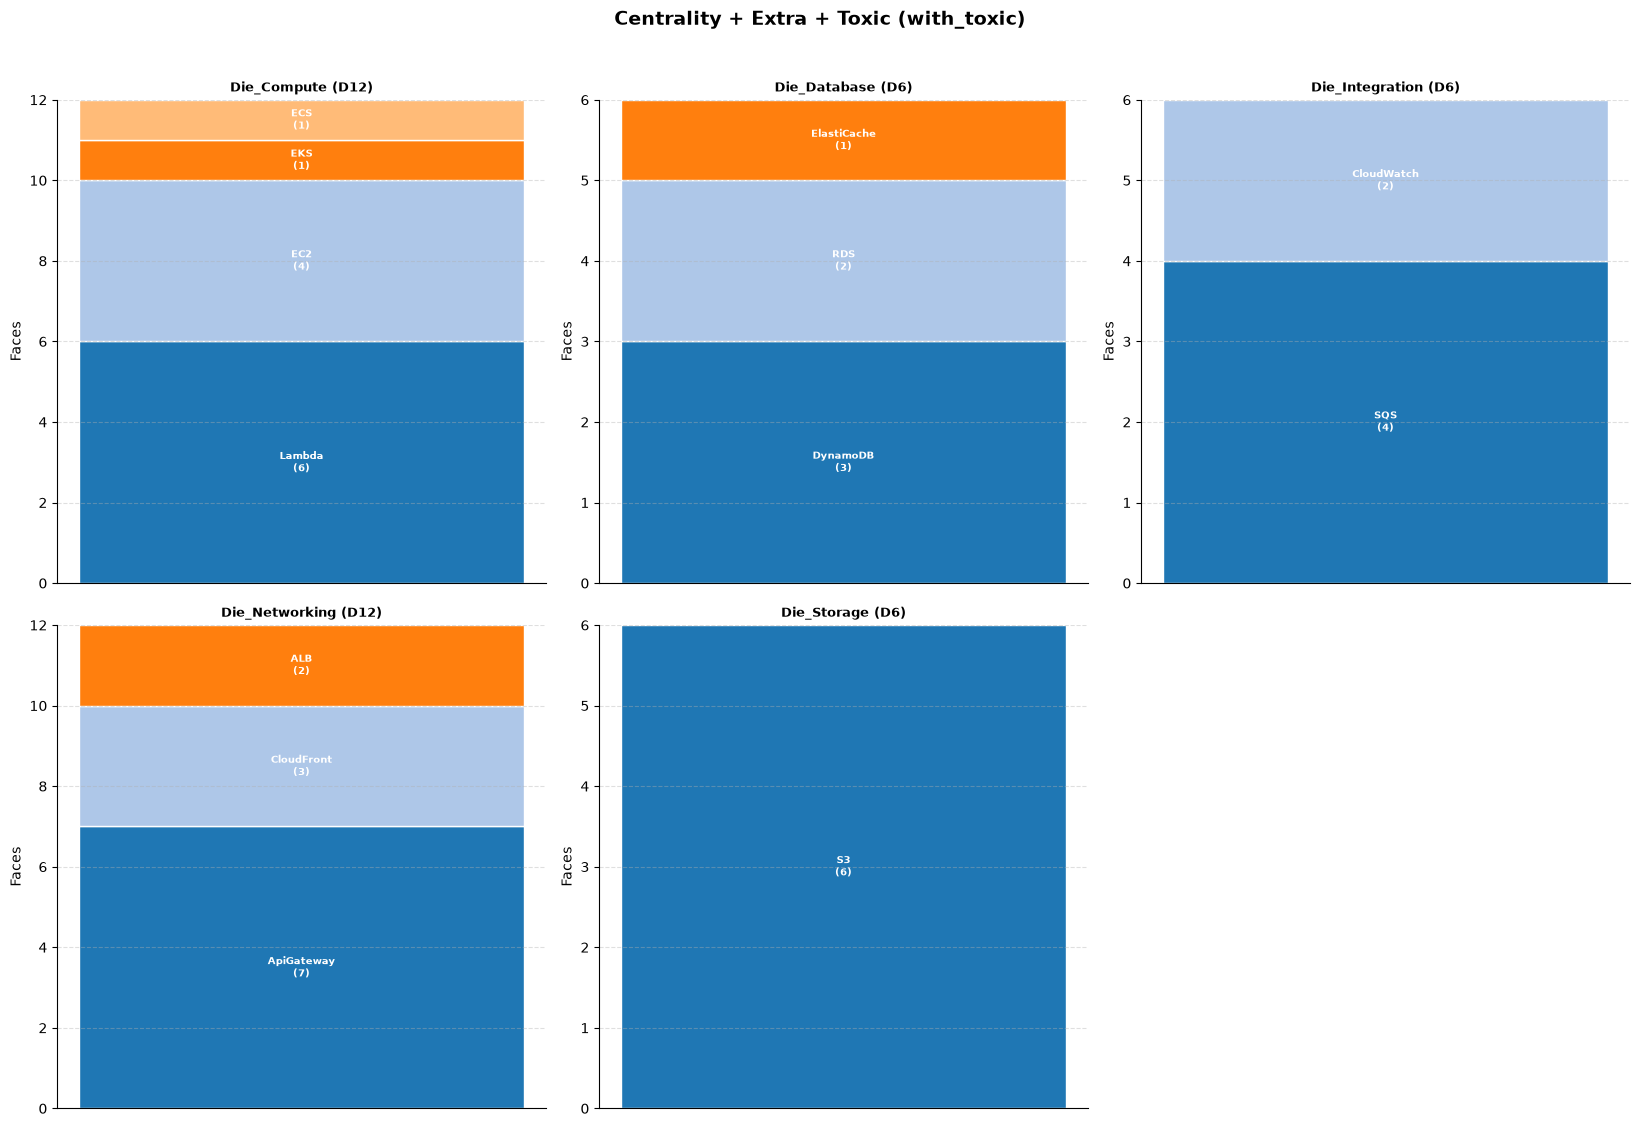

In [12]:
def plot_dice_set(df_opt: pl.DataFrame, title: str):
    summary = df_opt.select(['die_id', 'die_shape']).unique().sort('die_id')
    die_ids = summary['die_id'].to_list()
    shapes = summary['die_shape'].to_list()

    n_dice = len(die_ids)
    n_cols = min(3, n_dice) if n_dice > 0 else 1
    n_rows = int(np.ceil(n_dice / n_cols)) if n_dice > 0 else 1

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 5.5 * n_rows), squeeze=False)
    axes = axes.reshape(-1)
    cmap = plt.get_cmap('tab20')

    for i, (die_id, shape) in enumerate(zip(die_ids, shapes)):
        ax = axes[i]
        df_die = df_opt.filter(pl.col('die_id') == die_id)
        n_total = int(shape.replace('d', ''))
        services = df_die['service'].to_list()
        faces = df_die['num_faces'].to_list()

        bottom = 0
        for j, (serv, val) in enumerate(zip(services, faces)):
            ax.bar(0, val, bottom=bottom, color=cmap(j % 20), edgecolor='white', width=0.5)
            ax.text(0, bottom + val / 2, f"{serv}\n({val})", ha='center', va='center',
                    fontsize=7, color='white', fontweight='bold')
            bottom += val

        ax.set_ylim(0, n_total)
        die_title = f"{die_id} ({shape.upper()})"
        if die_id.startswith("Die_Extra"):
            die_title += " *"
        ax.set_title(die_title, fontweight='bold', fontsize=9)
        ax.set_xticks([])
        ax.set_ylabel('Faces')

    for k in range(n_dice, len(axes)):
        axes[k].axis('off')

    plt.suptitle(title, fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


plot_dice_set(faces_table, f"Centrality + Extra + Toxic ({design_report['winner']})")

## 8. Simulation of 1000 Rolls (Final Rules Check)

In [13]:
def simulate_roll(df_opt: pl.DataFrame, rng: np.random.Generator) -> list:
    selected = []
    for die_id, df_die in df_opt.group_by('die_id', maintain_order=True):
        shape = df_die['die_shape'].first()
        n_total = int(shape.replace('d', ''))
        services = df_die['service'].to_list()
        faces = df_die['num_faces'].to_list()
        prob = np.array(faces) / n_total
        selected.append(rng.choice(services, p=prob))
    return selected


def simulate_variant(df_opt: pl.DataFrame, G: nx.Graph = None, n_rolls: int = 1000, seed: int = 420) -> dict:
    if G is None:
        G = G_cooc_master
    rolls = []
    total_repeated = 0
    total_inconsistencies = 0

    rng = np.random.default_rng(seed)
    for _ in range(n_rolls):
        roll = simulate_roll(df_opt, rng)
        if len(roll) != len(set(roll)):
            total_repeated += 1
        if any(are_incompatible(s1, s2, G) for s1, s2 in combinations(roll, 2)):
            total_inconsistencies += 1
        rolls.append(" | ".join(sorted(roll)))

    df_results = pl.DataFrame({'architecture': rolls})
    df_summary = (
        df_results.group_by('architecture').len(name='frequency')
        .with_columns((pl.col('frequency') / n_rolls * 100).round(2).alias('percentage_%'))
        .sort(['frequency', 'architecture'], descending=[True, False])
    )

    return {
        'df_summary': df_summary,
        'repeated': total_repeated,
        'inconsistencies': total_inconsistencies,
        'unique_architectures': df_summary.height,
        'n_rolls': n_rolls,
    }


simulation_result = simulate_variant(faces_table, G_cooc_master, n_rolls=1000)

print("=" * 70)
print(f"Centrality + Extra + Toxic ({design_report['winner']})")
print("=" * 70)
print(f"Repeated: {simulation_result['repeated']} ({simulation_result['repeated'] / simulation_result['n_rolls'] * 100:.1f}%)")
print(
    f"Incompatible: {simulation_result['inconsistencies']} ({simulation_result['inconsistencies'] / simulation_result['n_rolls'] * 100:.1f}%)")
print(f"Unique: {simulation_result['unique_architectures']} of {simulation_result['n_rolls']}")

if simulation_result['inconsistencies'] == 0:
    print("\n>>> No roll broke the incompatibility rule. OK.")
else:
    print("\n>>> WARNING: some rolls had incompatible services together.")

TOP_N = 10
print(f"\nTop {TOP_N} most common:")
with pl.Config(tbl_rows=TOP_N, fmt_str_lengths=100):
    print(simulation_result['df_summary'].head(TOP_N))

print(f"\nTop {TOP_N} least common:")
with pl.Config(tbl_rows=TOP_N, fmt_str_lengths=100):
    print(simulation_result['df_summary'].tail(TOP_N))

Centrality + Extra + Toxic (with_toxic)
Repeated: 0 (0.0%)
Incompatible: 0 (0.0%)
Unique: 70 of 1000

>>> No roll broke the incompatibility rule. OK.

Top 10 most common:
shape: (10, 3)
┌──────────────────────────────────────────────────┬───────────┬──────────────┐
│ architecture                                     ┆ frequency ┆ percentage_% │
│ ---                                              ┆ ---       ┆ ---          │
│ str                                              ┆ u32       ┆ f64          │
╞══════════════════════════════════════════════════╪═══════════╪══════════════╡
│ ApiGateway | DynamoDB | Lambda | S3 | SQS        ┆ 89        ┆ 8.9          │
│ ApiGateway | Lambda | RDS | S3 | SQS             ┆ 60        ┆ 6.0          │
│ ApiGateway | CloudWatch | DynamoDB | Lambda | S3 ┆ 55        ┆ 5.5          │
│ ApiGateway | EC2 | RDS | S3 | SQS                ┆ 53        ┆ 5.3          │
│ ApiGateway | DynamoDB | EC2 | S3 | SQS           ┆ 52        ┆ 5.2          │
│ CloudFront |

## 9. Final Report

In [14]:
top = simulation_result['df_summary'].row(0, named=True)
bottom = simulation_result['df_summary'].row(-1, named=True)

df_report = pl.DataFrame([{
    'variant': f"Centrality + Extra + Toxic ({design_report['winner']})",
    'n_dice': len(dice_set),
    'n_extra_dice_achieved': len(created_extra_dice),
    'services_covered': n_services_covered,
    'toxic_central_services_detected': len(design_report['toxic_central_extra']),
    'toxic_central_services_included': design_report['winner'] == 'with_toxic',
    'unique_architectures_1000': simulation_result['unique_architectures'],
    'most_common_combo': top['architecture'],
    'most_common_pct': top['percentage_%'],
    'least_common_combo': bottom['architecture'],
    'least_common_pct': bottom['percentage_%'],
    'rolls_with_repeats': simulation_result['repeated'],
    'incompatible_rolls': simulation_result['inconsistencies'],
}])
print(df_report)

OUTPUT_DIR = Path("output_analytics")
OUTPUT_DIR.mkdir(exist_ok=True)
df_report.write_csv(OUTPUT_DIR / "report_centrality.csv")
faces_table.write_csv(OUTPUT_DIR / "faces_centrality.csv")
print(f"Exported: {OUTPUT_DIR / 'report_centrality.csv'}")
print(f"Exported: {OUTPUT_DIR / 'faces_centrality.csv'}")

shape: (1, 13)
┌────────────┬────────┬────────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ variant    ┆ n_dice ┆ n_extra_di ┆ services_ ┆ … ┆ least_com ┆ least_com ┆ rolls_wit ┆ incompati │
│ ---        ┆ ---    ┆ ce_achieve ┆ covered   ┆   ┆ mon_combo ┆ mon_pct   ┆ h_repeats ┆ ble_rolls │
│ str        ┆ i64    ┆ d          ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│            ┆        ┆ ---        ┆ i64       ┆   ┆ str       ┆ f64       ┆ i64       ┆ i64       │
│            ┆        ┆ i64        ┆           ┆   ┆           ┆           ┆           ┆           │
╞════════════╪════════╪════════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ Centrality ┆ 5      ┆ 0          ┆ 13        ┆ … ┆ CloudFron ┆ 0.1       ┆ 0         ┆ 0         │
│ + Extra +  ┆        ┆            ┆           ┆   ┆ t | ECS | ┆           ┆           ┆           │
│ Toxic (wi… ┆        ┆            ┆           ┆   ┆ ElastiCac ┆           ┆